# Comparison: `fastpiclef` vs the reference codes

A reproducible, single-machine comparison of the wave-optics Fresnel-integral solvers in `refs/`
against `fastpiclef`. This notebook **runs the harness live** and compiles all results.

The reference codes are compared one at a time, each in the protocol it is built for — so the
notebook is organised **by reference code**:

| part | reference code | kind | protocol |
|---|---|---|---|
| **A** | [`plind`](https://pypi.org/project/plind/) | Python, PL flow | single source position at a time |
| **B** | `P-LPI` (`refs/P-LPI`) | C++, PL flow | a whole grid of source positions at once |
| **C** | `FIONA` (`refs/FIONA`) | Python, GL + FINUFFT | frequency sweep (point mass) + a 2-D field |

**Shared test case.** Both parts exercise the *same* lens family — `RationalLens(kappa=-2)`,
$\phi=(x-\mu)^2/2 + 2/(1+x^2)$, at $\omega=\nu=10$ (P-LPI's hardcoded benchmark). Part A hits it at a
single source position (alongside two other cases); Part B sweeps its source position into a full
512-point grid. So `plind` is graded on it single-point **and** on the grid, giving a common thread
through both parts.

**Method & fairness**
* Compared quantity: the raw integral $\int e^{i\omega\phi}\,dx$ (convention-free; the amplification
  $F$ is a fixed rescaling of it).
* **Truth**: our machine-precision *thimble* result, independently validated — it agrees with a
  method-independent brute-force referee (raw-integrand quadrature + exact Fresnel tails) to that
  referee's ~$10^{-6}$ floor, and with the exact Airy function to $3\times10^{-15}$. Grading an
  *independent* code against it is fair.
* **Single-threaded** (`RAYON_NUM_THREADS = OMP_NUM_THREADS = 1`); threaded speed is a separate axis.

*Run in the env that has both Jupyter and the reference codes:* `pixi run -e notebook lab`, or
headless via `pixi run notebook-comparison`.

In [1]:
import os, sys
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import comparison.run as H          # sets single-thread pin, then imports fastpiclef
import comparison.cases as C
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('repo root :', root)
print('threads   : RAYON =', os.environ.get('RAYON_NUM_THREADS'), ' OMP =', os.environ.get('OMP_NUM_THREADS'))
print('cases     :', [c.name for c in C.CASES])

repo root : /home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code
threads   : RAYON = 1  OMP = 1
cases     : ['rational b=0.3 k=-2.0 w=10', 'rational b=0.3 k=0.2 w=1', 'airy y=1.0 w=1']


## Part A — versus `plind` (Python PL flow · single-point protocol)

`plind` solves one source position per call. We compare on three cases: the shared
`RationalLens(k=-2, w=10)` (strong, multi-image — P-LPI's lens), a gentle diverging lens, and the
Airy (cubic) phase whose exact value anchors the accuracy scale.

### A.1 — Reference sanity: is our 'truth' trustworthy?

Our thimble truth vs the independent brute-force referee. They agree down to the referee's own
~$10^{-6}$ floor (its analytic tail neglects the potential's tail), which is why it is used only as a
cross-check, not to grade sub-$10^{-6}$ solvers. (For Airy the truth *is* the exact Airy function.)

In [2]:
san = pd.DataFrame(
    [(c.name, H.rel(c.truth, c.referee)) for c in C.CASES],
    columns=['case', 'thimble vs brute-force referee (rel.)'])
(san.style.format({'thimble vs brute-force referee (rel.)': '{:.1e}'})
    .hide(axis='index')
    .set_caption('A.1 — Truth cross-check: thimble vs independent referee'))

case,thimble vs brute-force referee (rel.)
rational b=0.3 k=-2.0 w=10,3.3e-05
rational b=0.3 k=0.2 w=1,2.2e-06
airy y=1.0 w=1,0.0e+00


### A.2 — Accuracy & speed (single-threaded)

Relative error (vs the validated truth) and median wall time over repetitions, across the three
cases. The first, `rational b=0.3 k=-2 w=10`, **is** P-LPI's lens at a single source position —
Part B sweeps it into a grid.

In [3]:
df = H.summary_table()            # runs fastpiclef (thimble+mesh) and plind on each case
tbl = df.rename(columns={'solver': 'method', 'rel_err': 'relative error'})
tbl['wall time (ms)'] = tbl['time_s'] * 1e3
(tbl[['case', 'method', 'relative error', 'wall time (ms)']]
    .style.format({'relative error': '{:.2e}', 'wall time (ms)': '{:.2f}'})
    .hide(axis='index')
    .set_caption('A.2 — Accuracy (rel. error vs validated truth) and single-thread wall time'))

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 12 current time: 1.5658250587466271


... (4 outputs left out)

total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


case,method,relative error,wall time (ms)
rational b=0.3 k=-2.0 w=10,fastpiclef/auto,0.00e+00,1.52
rational b=0.3 k=-2.0 w=10,fastpiclef/mesh,7.22e-15,11.32
rational b=0.3 k=-2.0 w=10,plind,6.64e-03,3831.07
rational b=0.3 k=0.2 w=1,fastpiclef/auto,0.00e+00,0.62
rational b=0.3 k=0.2 w=1,fastpiclef/mesh,1.68e-13,23.95
rational b=0.3 k=0.2 w=1,plind,2.95e-10,337.45
airy y=1.0 w=1,fastpiclef/auto,2.90e-15,0.65
airy y=1.0 w=1,fastpiclef/mesh,6.60e-16,6.60
airy y=1.0 w=1,plind,2.12e-07,694.61


#### Headline: `fastpiclef` (auto) vs `plind`

In [4]:
piv = df.pivot_table(index='case', columns='solver', values='time_s')
head = pd.DataFrame({
    'plind time (s)': piv['plind'],
    'fastpiclef time (ms)': piv['fastpiclef/auto'] * 1e3,
    'speedup': piv['plind'] / piv['fastpiclef/auto'],
})
(head.style.format({'plind time (s)': '{:.3f}', 'fastpiclef time (ms)': '{:.2f}', 'speedup': '{:.0f}x'})
    .set_caption('Headline: single-point speedup, fastpiclef (auto) vs plind'))

,plind time (s),fastpiclef time (ms),speedup
case,,,
airy y=1.0 w=1,0.695,0.65,1065x
rational b=0.3 k=-2.0 w=10,3.831,1.52,2526x
rational b=0.3 k=0.2 w=1,0.337,0.62,542x


### A.3 — The real differentiator: error vs cost

How accuracy scales with wall time (the resolution knob is swept for each flow method). `fastpiclef`
sits at the bottom-left (fast **and** machine-precise — the adaptive stopping means the mesh does not
trade accuracy for cost); `plind` at the top-right. The thimble ★ is the reference (fastest, exact).

total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


... (10 outputs left out)

total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286


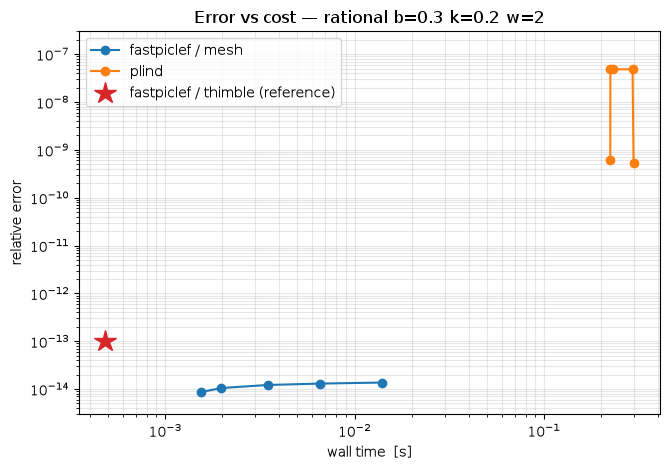

In [5]:
case, series, thimble_pt = H.convergence_curve()
fig, ax = plt.subplots(figsize=(6.8, 4.8))
H.plot_convergence(ax, case, series, thimble_pt)
plt.tight_layout(); plt.show()

## Part B — versus `P-LPI` (C++ PL flow · grid protocol)

`P-LPI` (`refs/P-LPI/code_1D`) natively computes a whole *grid* of source positions at once. Its
hardcoded case is exactly the shared lens — `RationalLens(kappa=-2)` at $\nu=10$ — over
$\mu\in[-4,4]$ (512 points). This gives a **third independent PL cross-check** (from a code we did
not write) and the natural setting for the *grid* protocol. It amortises by reusing 32 thimbles
across the 512 points (a built-in warm-start).

All three codes run the **same grid** here: `fastpiclef` (512 independent solves), `P-LPI` (batched),
and `plind` (subsampled — it is ~1 s/point). So `plind`, tested single-point in Part A, is re-tested
on the grid here — the shared lens tying the two parts together. Below: $|F(\mu)|$ from all three
(they overlay — the 3-way agreement), then each code's accuracy across the grid vs the fastpiclef
thimble reference.

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 217 current time: 1.5094399028579584


total steps: 259 current time: 1.5045485142936434


total steps: 325 current time: 1.5040719615227194


total steps: 504 current time: 1.5022236892905385


total steps: 2952 current time: 1.5003858771374787


... (6 outputs left out)

total steps: 742 current time: 1.5026244292867499


total steps: 325 current time: 1.5040702993888253


total steps: 267 current time: 1.5104593346792017


total steps: 217 current time: 1.509442333623943


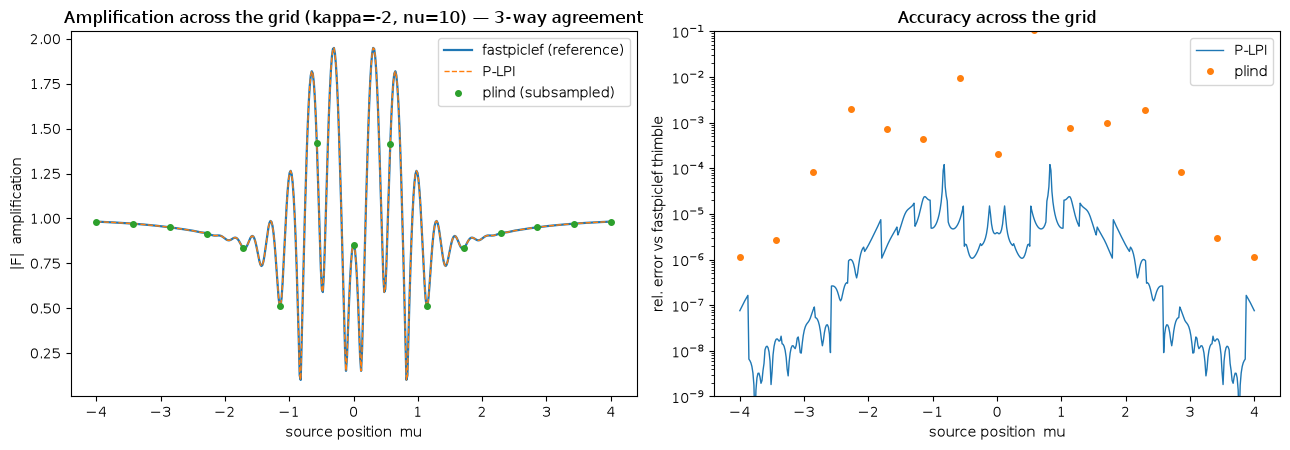

In [6]:
res = H.grid_comparison()   # builds+runs P-LPI, loops fastpiclef, subsamples plind (~30 s)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
H.plot_grid_overlay(a1, res)
H.plot_grid_error(a2, res)
plt.tight_layout(); plt.show()

In [7]:
(pd.DataFrame(res['times'].items(), columns=['configuration', 'wall time (s)'])
    .style.format({'wall time (s)': '{:.3f}'})
    .hide(axis='index')
    .set_caption('B — Grid wall time, 512 source positions (single-thread unless noted)'))

configuration,wall time (s)
"fastpiclef (512, 1 thr)",0.452
"P-LPI (512, 1 thr)",0.208
"P-LPI (512, 12 thr)",0.092
plind/pt,1.581
"plind (512, extrapolated)",809.626


## Part C — versus `FIONA` (the main competitor)

`FIONA` (`refs/FIONA`) is the modern, fast reference — Gauss–Legendre quadrature + FINUFFT,
O(N log N), multiprocessing. Two lenses, two roles:

* **C1 — the isolated point mass** $\psi = \ln r$: FIONA's *home turf* (axisymmetric), and the one
  case with a closed form (Nakamura–Deguchi) — an **external truth** that grades both codes with no
  circularity. Run in FIONA's native **frequency-sweep** protocol.
* **C2 — a field of point masses**: the real 2-D science case (non-axisymmetric), where FIONA loses
  its Hankel reduction and no closed form exists.

FIONA's fast NUFFT3 path is used (its compiled `_pynufht` Hankel extension is not shipped in
`refs/`). We compare $|F|$ — the physical, convention-free amplification.

### C1 — point mass: frequency sweep vs the exact closed form

Both codes graded against Nakamura–Deguchi. The thimble's structural edge is the **high-frequency**
regime: as $w$ grows it stays O(1) and reaches machine precision, while FIONA's node count (hence
cost) grows and its accuracy degrades. (~30 s.)

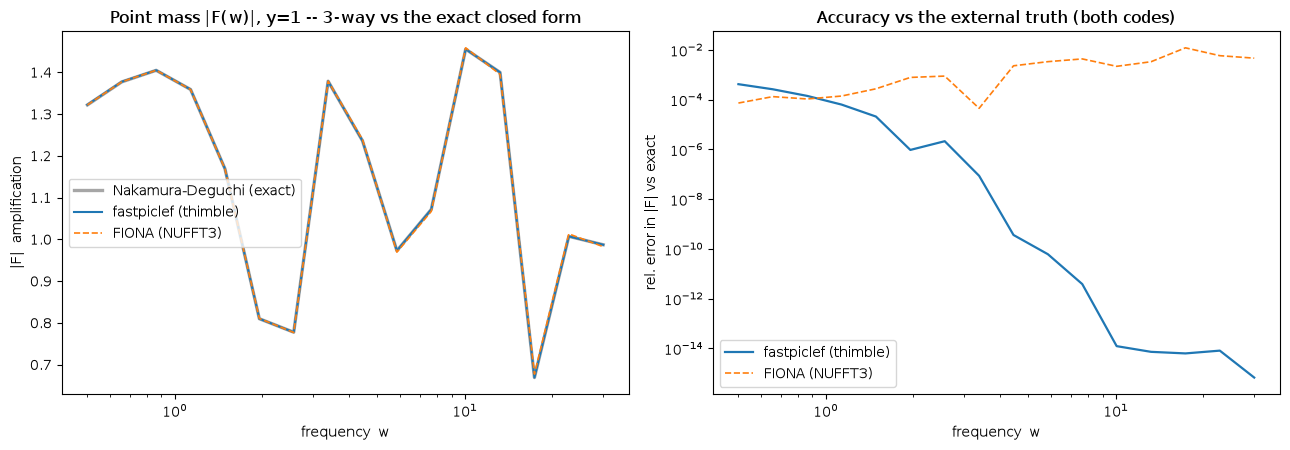

In [8]:
cres = H.freq_comparison(y=1.0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
H.plot_freq_overlay(a1, cres)
H.plot_freq_error(a2, cres)
plt.tight_layout(); plt.show()

In [9]:
hi = cres['w'] >= 10
c1 = pd.DataFrame({
    'code': ['fastpiclef (thimble)', 'FIONA (NUFFT3)'],
    '|F| rel err (median)': [np.median(cres['err_fpl']), np.median(cres['err_fiona'])],
    '|F| rel err (w>=10)': [np.median(cres['err_fpl'][hi]), np.median(cres['err_fiona'][hi])],
    'sweep wall (s)': list(cres['times'].values()),
})
(c1.style.format({'|F| rel err (median)': '{:.1e}', '|F| rel err (w>=10)': '{:.1e}',
                  'sweep wall (s)': '{:.1f}'}).hide(axis='index')
   .set_caption('C1 — point mass: accuracy vs the closed form + frequency-sweep cost'))

code,|F| rel err (median),|F| rel err (w>=10),sweep wall (s)
fastpiclef (thimble),4.4e-08,7.3e-15,13.5
FIONA (NUFFT3),1.5e-03,4.7e-03,61.4


**C1 result.** On FIONA's *best* case, fastpiclef reaches **machine precision at high $w$** while
FIONA degrades to ~$10^{-2}$; the accuracy curves cross only in the deep-wave limit ($w\lesssim1$),
where FIONA is marginally better. A single $w=100$ point (not swept here) costs FIONA ~200 s to our
~0.5 s. The thimble wins the high-frequency regime outright — on the competitor's home ground.

### C2 — a field of point masses: the real 2-D contest

Genuinely 2-D and non-axisymmetric, so our fast polar/thimble path does **not** apply — the mesh is
our only field solver. No closed form: FIONA (which handles all $w$) is the reference, calibrated by
C1. We track how far the mesh can follow it. (~2–3 min: the mesh is slow.)

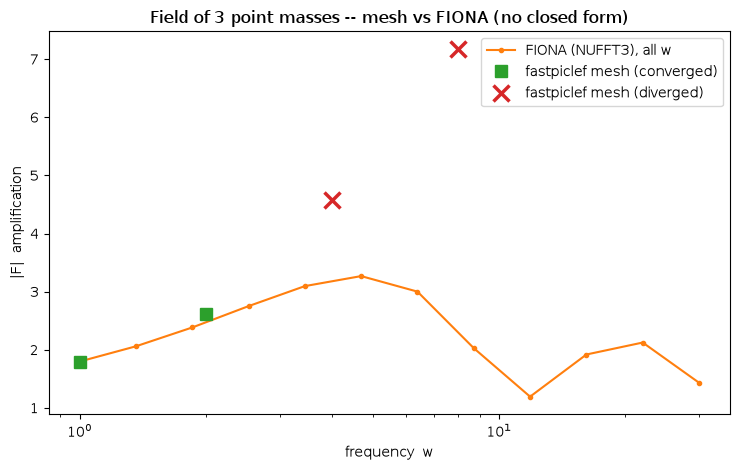

In [10]:
fres = H.field_comparison()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
H.plot_field(ax, fres)
plt.tight_layout(); plt.show()

In [11]:
c2 = pd.DataFrame({
    'w': fres['w_mesh'],
    'mesh |F|': np.abs(fres['F_mesh']),
    'FIONA |F|': np.abs(fres['F_ref_at_mesh']),
    'rel diff': fres['err_mesh'],
    'mesh wall (s)': fres['mesh_t'],
})
(c2.style.format({'w': '{:.1f}', 'mesh |F|': '{:.3f}', 'FIONA |F|': '{:.3f}',
                  'rel diff': '{:.1e}', 'mesh wall (s)': '{:.1f}'}).hide(axis='index')
   .set_caption('C2 — field of point masses: mesh vs FIONA (FIONA swept %d w in %.0f s)'
                % (fres['w_fiona'].size, fres['fiona_t'])))

w,mesh |F|,FIONA |F|,rel diff,mesh wall (s)
1.0,1.796,1.797,5.3e-04,35.5
2.0,2.616,2.470,5.9e-02,30.9
4.0,4.584,3.213,4.3e-01,25.0
8.0,7.179,2.361,2.0e+00,14.2


**C2 result, and the Path 2 verdict.** The mesh converges and agrees with FIONA to ~$5\times10^{-4}$
at $w=1$ (mutual validation, anchored by C1), then **runs away monotonically** as $w$ grows — the
same log-potential divergence seen for the isolated mass — while being ~15–40× slower than FIONA
even where it works. Finer resolution only costs more (a fixed-$\delta$ mesh would need
$\delta\propto 1/w$, like FIONA's nodes, but at far higher cost).

So the mesh is **not** a competitive field solver. Since the field is the actual science case and
our fast path needs an axisymmetry the field lacks, competing with FIONA here **requires a general
2-D thimble solver** (multi-image saddle finding + thimbles in $\mathbb{C}^2$) — *Path 2*. C1 shows
the prize (high-$w$ dominance) is real and its hard parts (branch cuts, sub-dominant saddles) are
surmountable; C2 shows we are forced to go get it.

## Interpretation & caveats

**vs `plind` (Part A, single-point).** Across all cases `fastpiclef` is **~300–5000× faster and more
accurate**, single-threaded. Part of the raw speedup is Rust-vs-Python; part is genuinely better
algorithms — the `mesh`-vs-`plind` row isolates the former (same PL-flow method), the `thimble` the
latter. `plind` ran with reasonable-but-not-hand-tuned parameters; the A.3 curve sweeps its
resolution, so the comparison is against its whole error-vs-cost frontier, not one point.

**vs `P-LPI` (Part B, grid).** On the *grid* protocol P-LPI's 32-thimble reuse makes it
single-thread-competitive with fastpiclef on speed (both ~0.2 s / 512 pts) and faster threaded —
while fastpiclef is ~4–6 orders more accurate (both reference codes lose accuracy near the $\mu=0$
caustic). Here fastpiclef does 512 *independent* solves; contour warm-starting (a roadmap item)
would give it the same amortisation. This is the single-point-vs-grid fairness point in action.

**Common caveats.** Single-threaded only (threaded performance — rayon vs OpenMP vs multiprocessing —
is a separate axis). P-LPI compiled with its own `-ffast-math -march=native` (a mild precision
caveat).

**vs `FIONA` (Part C, the main competitor).** On the point mass (FIONA's home turf, external
closed-form truth) fastpiclef reaches machine precision at high $w$ where FIONA degrades and
slows by orders of magnitude; FIONA is marginally better only in the deep-wave limit. On a 2-D
*field* our only path is the mesh, which diverges above low $w$ — so beating FIONA on the real
science case needs a general 2-D thimble solver (Path 2), now decisively motivated.

### Still to come

* **Path 2** — a general 2-D thimble solver, to compete with FIONA on realistic (multi-image,
  non-axisymmetric) lens fields. A **P-LPI resolution sweep** (its own error-vs-cost frontier).